In [ ]:
#Assignment 1
# Basic Libraries
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.preprocessing import StandardScaler

# Clustering
from sklearn.cluster import KMeans

# Evaluation
from sklearn.metrics import silhouette_score

In [ ]:
airlines = pd.read_excel('/content/EastWestAirlines.xlsx')

airlines.head()

,ID#,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
0,1,28143,0,1,1,1,174,1,0,0,7000,0
1,2,19244,0,1,1,1,215,2,0,0,6968,0
2,3,41354,0,1,1,1,4123,4,0,0,7034,0
3,4,14776,0,1,1,1,500,1,0,0,6952,0
4,5,97752,0,4,1,1,43300,26,2077,4,6935,1


In [ ]:
airlines.info()

airlines.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3999 entries, 0 to 3998
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   ID#                3999 non-null   int64
 1   Balance            3999 non-null   int64
 2   Qual_miles         3999 non-null   int64
 3   cc1_miles          3999 non-null   int64
 4   cc2_miles          3999 non-null   int64
 5   cc3_miles          3999 non-null   int64
 6   Bonus_miles        3999 non-null   int64
 7   Bonus_trans        3999 non-null   int64
 8   Flight_miles_12mo  3999 non-null   int64
 9   Flight_trans_12    3999 non-null   int64
 10  Days_since_enroll  3999 non-null   int64
 11  Award?             3999 non-null   int64
dtypes: int64(12)
memory usage: 375.0 KB


,ID#,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
count,3999.000000,3.999000e+03,3999.000000,3999.000000,3999.000000,3999.000000,3999.000000,3999.00000,3999.000000,3999.000000,3999.00000,3999.000000
mean,2014.819455,7.360133e+04,144.114529,2.059515,1.014504,1.012253,17144.846212,11.60190,460.055764,1.373593,4118.55939,0.370343
std,1160.764358,1.007757e+05,773.663804,1.376919,0.147650,0.195241,24150.967826,9.60381,1400.209171,3.793172,2065.13454,0.482957
min,1.000000,0.000000e+00,0.000000,1.000000,1.000000,1.000000,0.000000,0.00000,0.000000,0.000000,2.00000,0.000000
25%,1010.500000,1.852750e+04,0.000000,1.000000,1.000000,1.000000,1250.000000,3.00000,0.000000,0.000000,2330.00000,0.000000
50%,2016.000000,4.309700e+04,0.000000,1.000000,1.000000,1.000000,7171.000000,12.00000,0.000000,0.000000,4096.00000,0.000000
75%,3020.500000,9.240400e+04,0.000000,3.000000,1.000000,1.000000,23800.500000,17.00000,311.000000,1.000000,5790.50000,1.000000
max,4021.000000,1.704838e+06,11148.000000,5.000000,3.000000,5.000000,263685.000000,86.00000,30817.000000,53.000000,8296.00000,1.000000


In [ ]:
#Business Problem
'''Business Objective

To segment airline customers based on travel behavior.'''

#Business Constraints
'''Large customer data.
Clusters should be meaningful for marketing'''.

In [ ]:
#missing val
airlines.isnull().sum()

,0
ID#,0
Balance,0
Qual_miles,0
cc1_miles,0
cc2_miles,0
cc3_miles,0
Bonus_miles,0
Bonus_trans,0
Flight_miles_12mo,0
Flight_trans_12,0


In [ ]:
#duplicate val
airlines.duplicated().sum()

np.int64(0)

In [ ]:
#1MBD
airlines.mean(numeric_only=True)

#2MBD
airlines.var(numeric_only=True)

airlines.std(numeric_only=True)

#3MBD
airlines.skew(numeric_only=True)

#4MBD
airlines.kurt(numeric_only=True)

,0
ID#,-1.199648
Balance,44.157932
Qual_miles,67.689351
cc1_miles,-0.748508
cc2_miles,133.786489
cc3_miles,308.654728
Bonus_miles,13.630489
Bonus_trans,2.745737
Flight_miles_12mo,94.761019
Flight_trans_12,42.978152


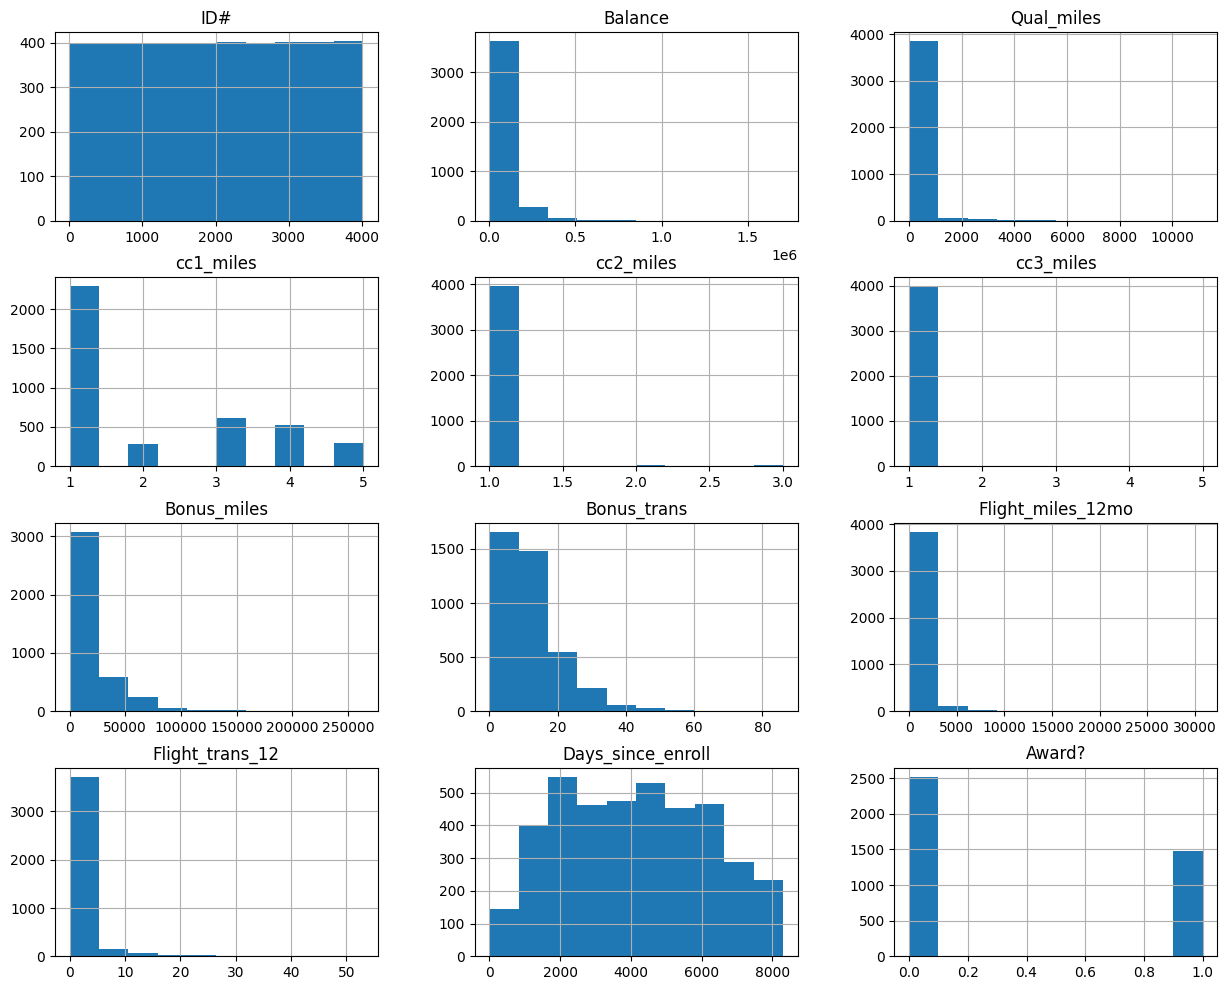

In [ ]:
#EDA
airlines.hist(figsize=(15,12))
plt.show()

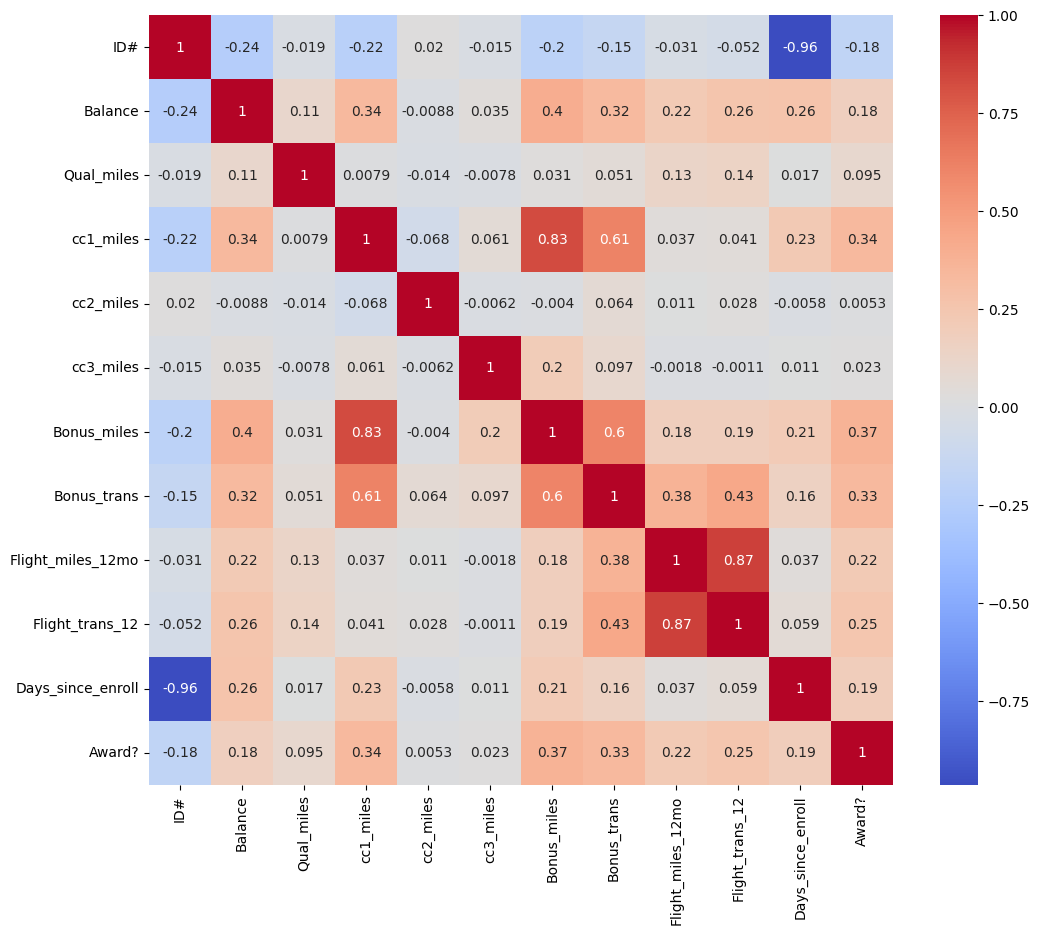

In [ ]:
#correlation heatmap
plt.figure(figsize=(12,10))
sns.heatmap(airlines.corr(), annot=True, cmap='coolwarm')
plt.show()

In [ ]:
#data scaling
scaler = StandardScaler()

scaled_data = scaler.fit_transform(airlines)

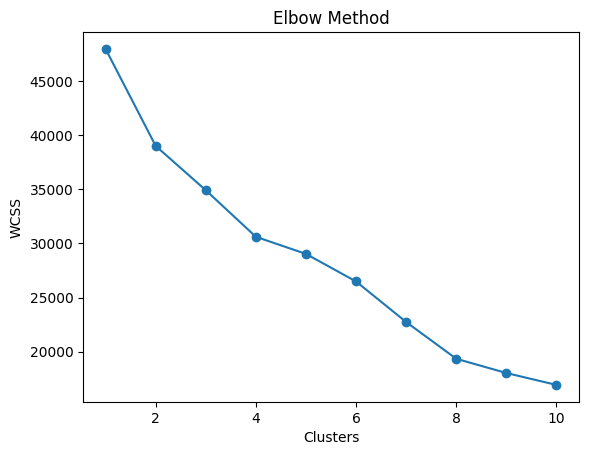

In [ ]:
#elbow method
wcss = []

for i in range(1,11):
    kmeans = KMeans(n_clusters=i, random_state=42)
    kmeans.fit(scaled_data)
    wcss.append(kmeans.inertia_)

plt.plot(range(1,11), wcss, marker='o')
plt.xlabel("Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

In [ ]:
#finale k-means model
kmeans = KMeans(n_clusters=4, random_state=42)

clusters = kmeans.fit_predict(scaled_data)

airlines['Cluster'] = clusters

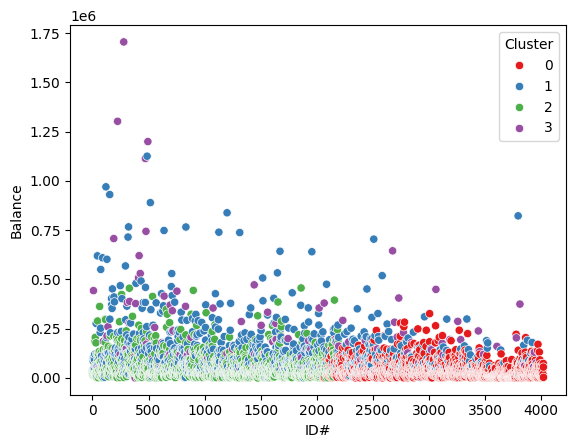

In [ ]:
#cluster visualization
sns.scatterplot(
    x=airlines.iloc[:,0],
    y=airlines.iloc[:,1],
    hue=airlines['Cluster'],
    palette='Set1'
)

plt.show()

In [ ]:
#silhouette score
score = silhouette_score(scaled_data, clusters)

print("Silhouette Score:", score)

Silhouette Score: 0.22808887010836637


In [ ]:
#cluster insignts
airlines.groupby('Cluster').mean()

,ID#,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
Cluster,,,,,,,,,,,,
0,3133.055231,39898.197531,106.287199,1.388564,1.016894,1.000000,6271.906433,7.831709,201.923977,0.600390,2155.511371,0.211826
1,1532.492552,127734.216485,160.202582,3.959285,1.001986,1.047666,45887.323734,19.507448,371.256207,1.117180,4977.380338,0.692155
2,1094.120278,56985.831149,96.370085,1.363917,1.018504,1.000771,5886.720894,7.996916,227.814187,0.703932,5713.395528,0.254433
3,1751.262821,194803.871795,810.397436,2.198718,1.038462,1.000000,32475.410256,27.737179,5510.717949,16.224359,4681.352564,0.820513


In [ ]:
#Interpretation
'''Customers are grouped based on flying patterns.
High-value customers can be identified.'''

#Business Benefits
'''Personalized offers.
Better loyalty programs.
Improved customer retention.'''

'Personalized offers.\nBetter loyalty programs.\nImproved customer retention.'

In [ ]:
#Assignment 2
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler

from sklearn.cluster import KMeans

from sklearn.metrics import silhouette_score

In [ ]:
crime = pd.read_csv('/content/crime_data.csv')

crime.head()

,Unnamed: 0,Murder,Assault,UrbanPop,Rape
0,Alabama,13.2,236,58,21.2
1,Alaska,10.0,263,48,44.5
2,Arizona,8.1,294,80,31.0
3,Arkansas,8.8,190,50,19.5
4,California,9.0,276,91,40.6


In [ ]:
crime.info()

crime.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  50 non-null     object 
 1   Murder      50 non-null     float64
 2   Assault     50 non-null     int64  
 3   UrbanPop    50 non-null     int64  
 4   Rape        50 non-null     float64
dtypes: float64(2), int64(2), object(1)
memory usage: 2.1+ KB


,Murder,Assault,UrbanPop,Rape
count,50.00000,50.000000,50.000000,50.000000
mean,7.78800,170.760000,65.540000,21.232000
std,4.35551,83.337661,14.474763,9.366385
min,0.80000,45.000000,32.000000,7.300000
25%,4.07500,109.000000,54.500000,15.075000
50%,7.25000,159.000000,66.000000,20.100000
75%,11.25000,249.000000,77.750000,26.175000
max,17.40000,337.000000,91.000000,46.000000


In [ ]:
#Business Problem
'''Business Objective

To identify crime-prone regions using clustering.'''

#Business Constraints
'''Different crime rates across regions.
Clusters must help law enforcement'''

In [ ]:
#missing val
crime.isnull().sum()

,0
Unnamed: 0,0
Murder,0
Assault,0
UrbanPop,0
Rape,0


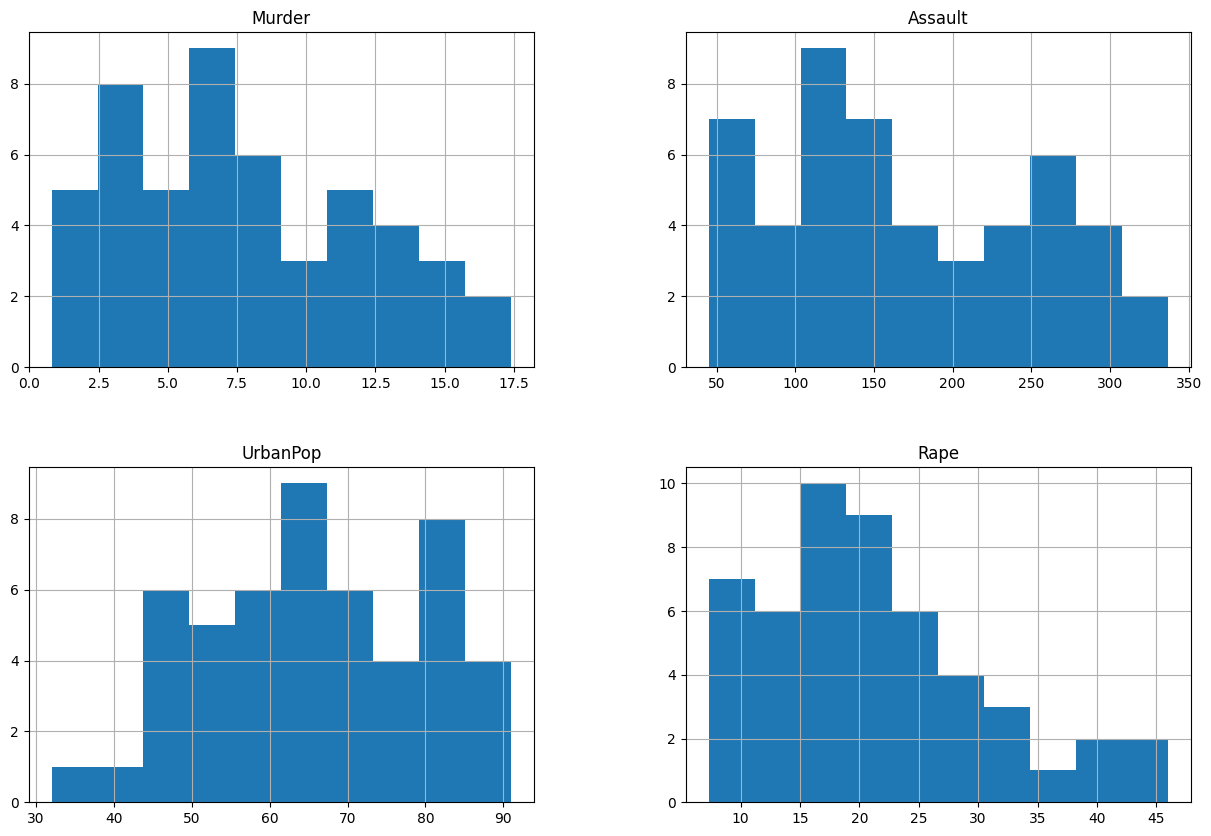

In [ ]:
#EDA
crime.hist(figsize=(15,10))
plt.show()

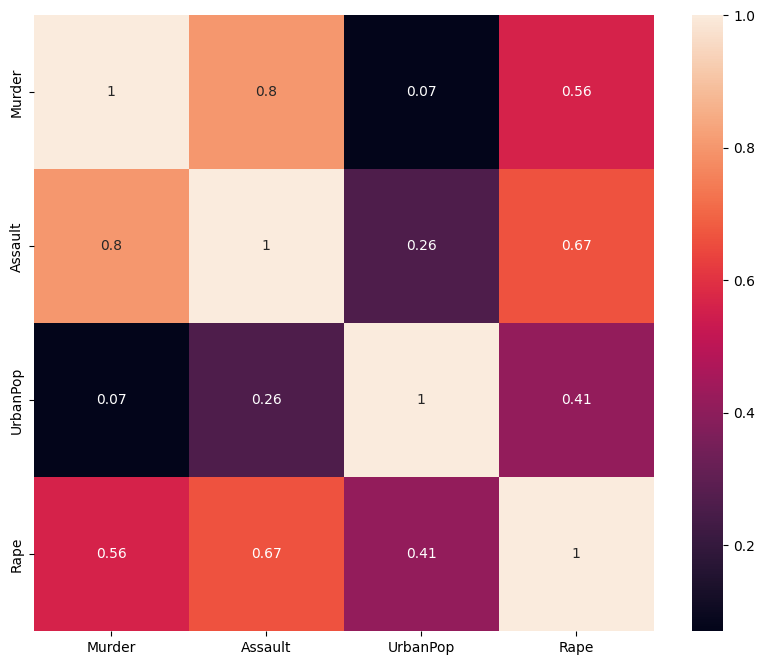

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

#heatmap
plt.figure(figsize=(10,8))
sns.heatmap(crime.drop('Unnamed: 0', axis=1).corr(), annot=True)
plt.show()

In [ ]:
#1MBD
crime.mean(numeric_only=True)

#2MBD
crime.var(numeric_only=True)

crime.std(numeric_only=True)


#3MBD
crime.skew(numeric_only=True)

#4MBD
crime.kurt(numeric_only=True)

,0
Murder,-0.827488
Assault,-1.053848
UrbanPop,-0.738360
Rape,0.353964


In [ ]:
#scaling
scaler = StandardScaler()

scaled_crime = scaler.fit_transform(crime.iloc[:,1:])

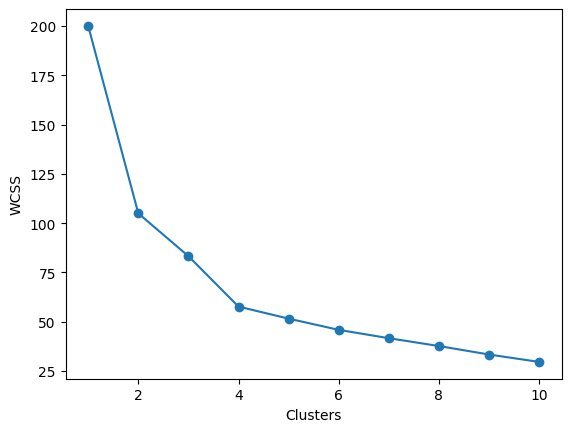

In [ ]:
#elbow method
wcss = []

for i in range(1,11):
    model = KMeans(n_clusters=i, random_state=42)

    model.fit(scaled_crime)

    wcss.append(model.inertia_)

plt.plot(range(1,11), wcss, marker='o')

plt.xlabel("Clusters")

plt.ylabel("WCSS")

plt.show()

In [ ]:
#final model
kmeans = KMeans(n_clusters=4, random_state=42)

crime['Cluster'] = kmeans.fit_predict(scaled_crime)

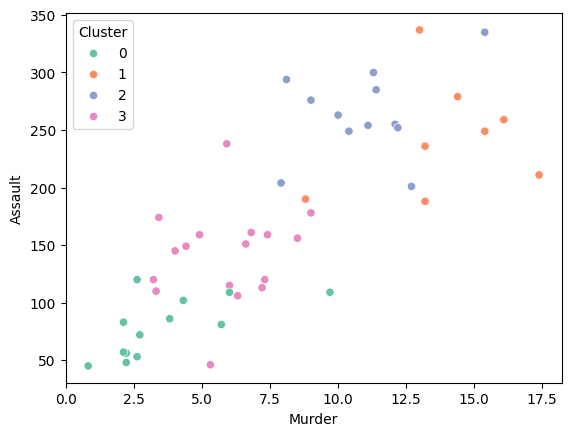

In [ ]:
#visualization
sns.scatterplot(
    x=crime.iloc[:,1],
    y=crime.iloc[:,2],
    hue=crime['Cluster'],
    palette='Set2'
)

plt.show()

In [ ]:
#silhouette score
score = silhouette_score(scaled_crime, crime['Cluster'])

print(score)

0.3441080718209351


In [ ]:
#cluster insights
crime.groupby('Cluster').mean(numeric_only=True)

,Murder,Assault,UrbanPop,Rape
Cluster,,,,
0,3.600000,78.538462,52.076923,12.176923
1,13.937500,243.625000,53.750000,21.412500
2,10.966667,264.000000,76.500000,33.608333
3,5.852941,141.176471,73.647059,19.335294


In [ ]:
#Business Benefits
'''Identifies high-crime areas.
Helps police resource allocation.
Improves crime prevention planning'''

In [ ]:
#Assignment: 3
insurance = pd.read_csv('/content/Insurance Dataset.csv')

insurance.head()

,Premiums Paid,Age,Days to Renew,Claims made,Income
0,2800,26,233,3890.076336,28000
1,2950,27,130,2294.444444,29500
2,3100,28,144,2564.545455,31000
3,3250,30,65,1978.260870,32500
4,3400,32,56,2009.090909,34000


In [ ]:
insurance.info()

insurance.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Premiums Paid  100 non-null    int64  
 1   Age            100 non-null    int64  
 2   Days to Renew  100 non-null    int64  
 3   Claims made    100 non-null    float64
 4   Income         100 non-null    int64  
dtypes: float64(1), int64(4)
memory usage: 4.0 KB


,Premiums Paid,Age,Days to Renew,Claims made,Income
count,100.000000,100.000000,100.000000,100.000000,100.000000
mean,12542.250000,46.110000,120.400000,12578.993367,102250.000000
std,6790.731666,13.887641,88.055767,13695.906762,43517.237964
min,2800.000000,23.000000,1.000000,1978.260870,28000.000000
25%,6975.000000,34.000000,56.000000,5220.648735,65125.000000
50%,11825.000000,45.000000,89.000000,8386.043907,102250.000000
75%,15475.000000,54.500000,186.500000,14670.889520,139375.000000
max,29900.000000,82.000000,321.000000,99676.744190,176500.000000


In [ ]:
#Business Problem
'''Objective

Segment insurance customers based on policy behavior.'''

In [ ]:
#missing val
insurance.isnull().sum()

,0
Premiums Paid,0
Age,0
Days to Renew,0
Claims made,0
Income,0


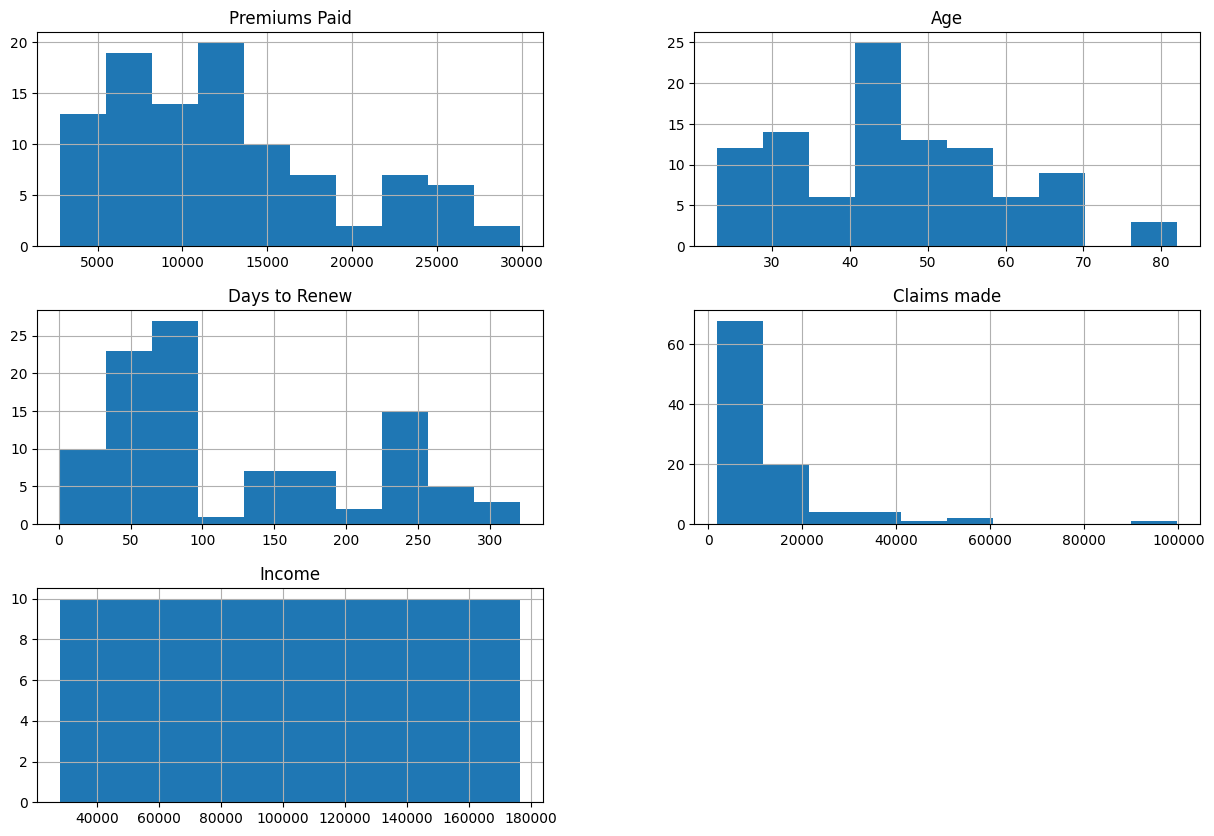

In [ ]:
#EDA
insurance.hist(figsize=(15,10))
plt.show()

In [ ]:
#scaling
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaled_insurance = scaler.fit_transform(
    insurance.select_dtypes(include=np.number)
)

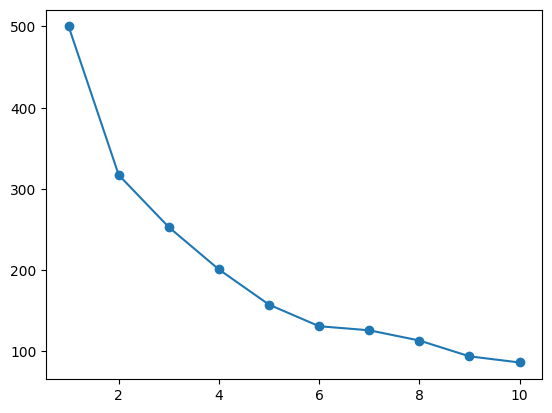

In [ ]:
#elbow method
wcss = []

for i in range(1,11):

    model = KMeans(n_clusters=i, random_state=42)

    model.fit(scaled_insurance)

    wcss.append(model.inertia_)

plt.plot(range(1,11), wcss, marker='o')

plt.show()

In [ ]:
#final model
kmeans = KMeans(n_clusters=3, random_state=42)

insurance['Cluster'] = kmeans.fit_predict(scaled_insurance)

In [ ]:
#cluster insights
insurance.groupby('Cluster').mean()

,Premiums Paid,Age,Days to Renew,Claims made,Income
Cluster,,,,,
0,12935.638298,43.382979,105.978723,10252.656442,115797.872340
1,22852.500000,61.050000,179.900000,31067.754659,153025.000000
2,5733.333333,40.939394,104.878788,4686.951234,52181.818182


In [ ]:
#Business Benefits
'''Better policy targeting.
Customer segmentation.
Personalized insurance plans.'''

In [ ]:
#Assignment 4
telco = pd.read_excel('/content/Telco_customer_churn.xlsx')

telco.head()

,Customer ID,Count,Quarter,Referred a Friend,Number of Referrals,Tenure in Months,Offer,Phone Service,Avg Monthly Long Distance Charges,Multiple Lines,...,Unlimited Data,Contract,Paperless Billing,Payment Method,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue
0,8779-QRDMV,1,Q3,No,0,1,NaN,No,0.00,No,...,No,Month-to-Month,Yes,Bank Withdrawal,39.65,39.65,0.00,20,0.00,59.65
1,7495-OOKFY,1,Q3,Yes,1,8,Offer E,Yes,48.85,Yes,...,Yes,Month-to-Month,Yes,Credit Card,80.65,633.30,0.00,0,390.80,1024.10
2,1658-BYGOY,1,Q3,No,0,18,Offer D,Yes,11.33,Yes,...,Yes,Month-to-Month,Yes,Bank Withdrawal,95.45,1752.55,45.61,0,203.94,1910.88
3,4598-XLKNJ,1,Q3,Yes,1,25,Offer C,Yes,19.76,No,...,Yes,Month-to-Month,Yes,Bank Withdrawal,98.50,2514.50,13.43,0,494.00,2995.07
4,4846-WHAFZ,1,Q3,Yes,1,37,Offer C,Yes,6.33,Yes,...,Yes,Month-to-Month,Yes,Bank Withdrawal,76.50,2868.15,0.00,0,234.21,3102.36


In [ ]:
telco.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 30 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Customer ID                        7043 non-null   object 
 1   Count                              7043 non-null   int64  
 2   Quarter                            7043 non-null   object 
 3   Referred a Friend                  7043 non-null   object 
 4   Number of Referrals                7043 non-null   int64  
 5   Tenure in Months                   7043 non-null   int64  
 6   Offer                              3166 non-null   object 
 7   Phone Service                      7043 non-null   object 
 8   Avg Monthly Long Distance Charges  7043 non-null   float64
 9   Multiple Lines                     7043 non-null   object 
 10  Internet Service                   7043 non-null   object 
 11  Internet Type                      5517 non-null   objec

In [ ]:
#handling categorical variable
telco_encoded = pd.get_dummies(telco, drop_first=True)

In [ ]:
#missing val
telco_encoded.isnull().sum()

,0
Count,0
Number of Referrals,0
Tenure in Months,0
Avg Monthly Long Distance Charges,0
Avg Monthly GB Download,0
...,...
Contract_One Year,0
Contract_Two Year,0
Paperless Billing_Yes,0
Payment Method_Credit Card,0


In [ ]:
#scaling
scaler = StandardScaler()

scaled_telco = scaler.fit_transform(telco_encoded)

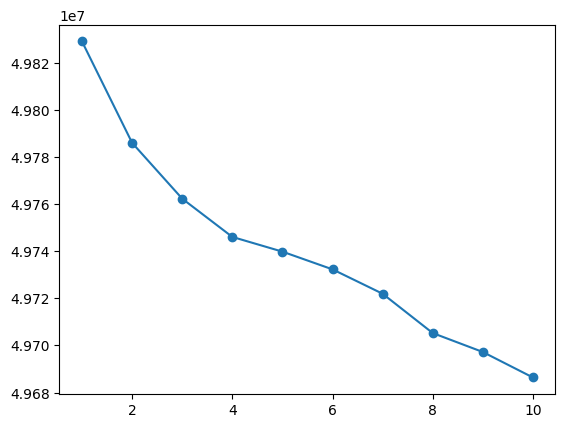

In [ ]:
#elbow method
wcss = []

for i in range(1,11):

    model = KMeans(n_clusters=i, random_state=42)

    model.fit(scaled_telco)

    wcss.append(model.inertia_)

plt.plot(range(1,11), wcss, marker='o')

plt.show()

In [ ]:
#final model
kmeans = KMeans(n_clusters=4, random_state=42)

telco_encoded['Cluster'] = kmeans.fit_predict(scaled_telco)

In [ ]:
#cluster insights
telco_encoded.groupby('Cluster').mean()

,Count,Number of Referrals,Tenure in Months,Avg Monthly Long Distance Charges,Avg Monthly GB Download,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,...,Premium Tech Support_Yes,Streaming TV_Yes,Streaming Movies_Yes,Streaming Music_Yes,Unlimited Data_Yes,Contract_One Year,Contract_Two Year,Paperless Billing_Yes,Payment Method_Credit Card,Payment Method_Mailed Check
Cluster,,,,,,,,,,,,,,,,,,,,,
0,1.0,2.179747,29.932278,24.876342,0.675949,22.150158,661.284297,1.695399,0.917722,751.037810,...,0.006962,0.000000,0.001266,0.001266,0.012025,0.235443,0.407595,0.287342,0.610127,0.091139
1,1.0,3.935065,63.873593,28.323420,28.270130,93.394286,5991.372121,1.971887,10.121212,1777.270095,...,0.732468,0.790476,0.833766,0.761905,0.870130,0.255411,0.666667,0.674459,0.436364,0.019048
2,1.0,1.313152,24.780674,24.380642,24.645148,86.539896,2227.682698,2.247622,8.003208,568.445100,...,0.198476,0.541700,0.530072,0.458300,0.868083,0.176423,0.076985,0.780273,0.220128,0.031275
3,1.0,1.368798,24.933848,15.918644,27.180265,53.703666,1400.231863,1.795932,8.390298,341.134135,...,0.381477,0.244212,0.245314,0.255237,0.857773,0.244212,0.152701,0.546858,0.403528,0.077729


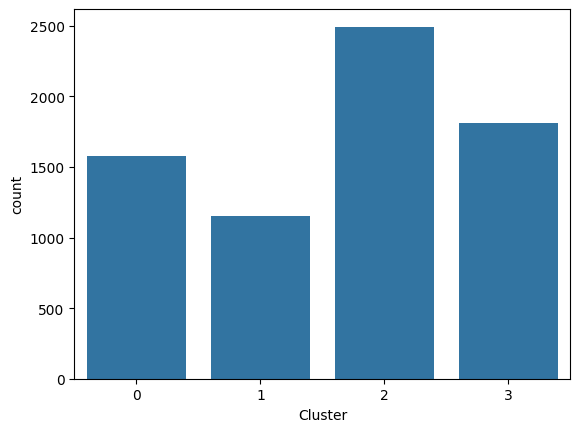

In [ ]:
#visualization
sns.countplot(x=telco_encoded['Cluster'])

plt.show()

In [ ]:
#Business Benefits
'''Identifies churn-prone customers.
Helps retention campaigns.
Improves telecom services.'''

In [ ]:
#Assignment:4
auto = pd.read_csv('/content/AutoInsurance.csv')

auto.head()

,Customer,State,Customer Lifetime Value,Response,Coverage,Education,Effective To Date,EmploymentStatus,Gender,Income,...,Months Since Policy Inception,Number of Open Complaints,Number of Policies,Policy Type,Policy,Renew Offer Type,Sales Channel,Total Claim Amount,Vehicle Class,Vehicle Size
0,BU79786,Washington,2763.519279,No,Basic,Bachelor,2/24/11,Employed,F,56274,...,5,0,1,Corporate Auto,Corporate L3,Offer1,Agent,384.811147,Two-Door Car,Medsize
1,QZ44356,Arizona,6979.535903,No,Extended,Bachelor,1/31/11,Unemployed,F,0,...,42,0,8,Personal Auto,Personal L3,Offer3,Agent,1131.464935,Four-Door Car,Medsize
2,AI49188,Nevada,12887.431650,No,Premium,Bachelor,2/19/11,Employed,F,48767,...,38,0,2,Personal Auto,Personal L3,Offer1,Agent,566.472247,Two-Door Car,Medsize
3,WW63253,California,7645.861827,No,Basic,Bachelor,1/20/11,Unemployed,M,0,...,65,0,7,Corporate Auto,Corporate L2,Offer1,Call Center,529.881344,SUV,Medsize
4,HB64268,Washington,2813.692575,No,Basic,Bachelor,3/2/2011,Employed,M,43836,...,44,0,1,Personal Auto,Personal L1,Offer1,Agent,138.130879,Four-Door Car,Medsize


In [ ]:
auto.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9134 entries, 0 to 9133
Data columns (total 24 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Customer                       9134 non-null   object 
 1   State                          9134 non-null   object 
 2   Customer Lifetime Value        9134 non-null   float64
 3   Response                       9134 non-null   object 
 4   Coverage                       9134 non-null   object 
 5   Education                      9134 non-null   object 
 6   Effective To Date              9134 non-null   object 
 7   EmploymentStatus               9134 non-null   object 
 8   Gender                         9134 non-null   object 
 9   Income                         9134 non-null   int64  
 10  Location Code                  9134 non-null   object 
 11  Marital Status                 9134 non-null   object 
 12  Monthly Premium Auto           9134 non-null   i

In [ ]:
#converting categorical var
auto_encoded = pd.get_dummies(auto, drop_first=True)

In [ ]:
#missing val
auto_encoded.isnull().sum()

,0
Customer Lifetime Value,0
Income,0
Monthly Premium Auto,0
Months Since Last Claim,0
Months Since Policy Inception,0
...,...
Vehicle Class_SUV,0
Vehicle Class_Sports Car,0
Vehicle Class_Two-Door Car,0
Vehicle Size_Medsize,0


In [ ]:
#scaling
scaler = StandardScaler()

scaled_auto = scaler.fit_transform(auto_encoded)

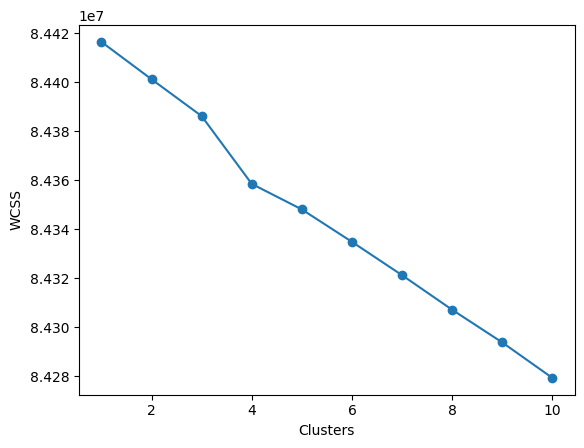

In [ ]:
#elbow method
wcss = []

for i in range(1,11):

    model = KMeans(n_clusters=i, random_state=42)

    model.fit(scaled_auto)

    wcss.append(model.inertia_)

plt.plot(range(1,11), wcss, marker='o')

plt.xlabel("Clusters")

plt.ylabel("WCSS")

plt.show()

In [ ]:
#final k-means model
kmeans = KMeans(n_clusters=4, random_state=42)

auto_encoded['Cluster'] = kmeans.fit_predict(scaled_auto)

In [ ]:
#cluster insights
auto_encoded.groupby('Cluster').mean()

,Customer Lifetime Value,Income,Monthly Premium Auto,Months Since Last Claim,Months Since Policy Inception,Number of Open Complaints,Number of Policies,Total Claim Amount,Customer_AA11235,Customer_AA16582,...,Sales Channel_Branch,Sales Channel_Call Center,Sales Channel_Web,Vehicle Class_Luxury Car,Vehicle Class_Luxury SUV,Vehicle Class_SUV,Vehicle Class_Sports Car,Vehicle Class_Two-Door Car,Vehicle Size_Medsize,Vehicle Size_Small
Cluster,,,,,,,,,,,,,,,,,,,,,
0,7964.762419,18925.961538,101.786713,14.930070,47.951049,0.206294,2.632867,562.008585,0.000000,0.000000,...,0.223776,0.216783,0.132867,0.017483,0.059441,0.160839,0.062937,0.290210,0.825175,0.129371
1,7880.998096,47770.034567,90.142834,15.520789,47.944888,0.373879,2.982064,347.095826,0.000163,0.000163,...,0.310452,0.188978,0.138594,0.012881,0.012555,0.193380,0.049405,0.185391,0.765531,0.140551
2,8788.606384,43431.740864,104.795127,12.596899,47.066445,0.326689,2.735327,545.984307,0.000000,0.000000,...,0.147287,0.245847,0.116279,0.037652,0.047619,0.178295,0.055371,0.341085,0.434109,0.374308
3,8040.249094,3508.388521,96.511038,14.934879,48.985099,0.476821,3.080022,652.577298,0.000000,0.000000,...,0.257174,0.177704,0.183223,0.024834,0.025938,0.222406,0.062362,0.197572,0.607616,0.290839


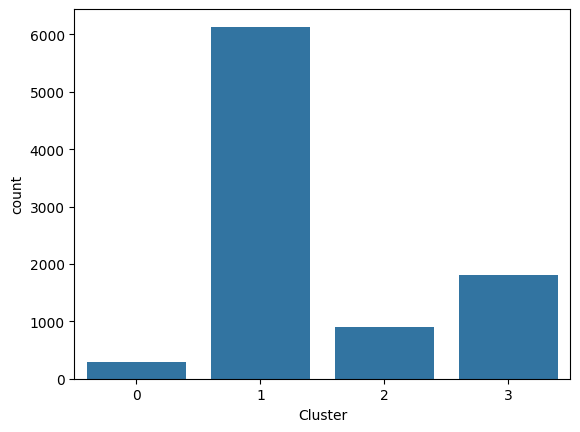

In [ ]:
#visualization
sns.countplot(x=auto_encoded['Cluster'])

plt.show()

In [ ]:
#Interpretation
'''Similar insurance customers are grouped together.
Helps identify risk groups.'''

#Business Benefits
'''Better premium planning.
Fraud detection.
Personalized insurance products.'''